# Quantum Hadamard Edge Detection on Trapped-Ion Hardware
## Synthetic Seismic Image Analysis — Quantinuum Helios

**Author:** Farah Almufawez  
**Hardware target:** Quantinuum Helios  
**Framework:** pytket + pytket-quantinuum  

---

### Structure of this notebook

| Section | Description 
|---------|-------------
| 1 | Install dependencies 
| 2 | Synthetic seismic dataset 
| 3 | Classical baselines (Sobel, SSIM, FOM) 
| 4 | QHED circuit (QPIE + auxiliary qubit) 
| 5 | Noiseless simulation and results 
| 6 | Resource estimation 
| 7 | Helios hardware submission 
> **Note:** Section 7 will not run until coordinator approval and Quantinuum credentials are available.

---
## Section 1 — Install Dependencies

In [5]:
import subprocess, sys

for pkg in ['pytket', 'pytket-qiskit', 'qiskit-aer', 'scikit-image', 'scipy', 'numpy', 'matplotlib']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
    print(f'installed: {pkg}')

print('All dependencies ready.')

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


installed: pytket


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


installed: pytket-qiskit


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


...

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


installed: scipy


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


installed: numpy
installed: matplotlib
All dependencies ready.


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import math, os
from collections import Counter
from scipy.ndimage import convolve
from scipy.signal import fftconvolve
from scipy.ndimage import distance_transform_edt
from skimage.metrics import structural_similarity as ssim
from pytket.circuit import Circuit, Op, OpType, QControlBox, StatePreparationBox

plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
print('Imports OK')

Imports OK


---
## Section 2 — Synthetic Seismic Dataset

Before implementing QHED, a set of synthetic binary seismic images is generated to provide controlled test cases with known structures and edge locations.

All images have dimensions (2^n \times 2^n) and are binarised (pixel values 0 or 1). This simplifies the proof-of-concept implementation and is compatible with the selected QPIE image encoding scheme.

The dataset includes four image types:

* **Seismic Reflectors** — horizontal layers representing simplified geological strata. The boundaries between adjacent layers form the target edges.

* **Seismic with Fault** — a seismic reflector image containing a vertical fault. One side of the image is shifted vertically to create a discontinuity similar to a geological fault structure.

* **Single Horizontal Edge** — a simple test case containing a single sharp boundary. Since the exact edge location is known, it provides a straightforward validation of the QHED implementation.

* **Checkerboard** — an image with alternating black and white pixels. Every neighbouring pixel differs, producing a high-density edge pattern that serves as a stress test for the algorithm.

Together, these images provide test cases with different edge densities and structural characteristics, allowing the behaviour of the QHED algorithm to be evaluated under a range of conditions.


In [7]:
def seismic_reflectors(n=3, seed=42):
    """Horizontal geological layer boundaries."""
    rng = np.random.default_rng(seed)
    size = 2**n
    image = np.zeros((size, size), dtype=np.float32)
    positions = sorted(rng.integers(1, size, size=3).tolist())
    positions = [0] + positions + [size]
    for i, (s, e) in enumerate(zip(positions[:-1], positions[1:])):
        image[s:e, :] = float(i % 2)
    return image

def seismic_with_fault(n=3, seed=7):
    """Seismic image with vertical fault discontinuity."""
    size = 2**n
    base = seismic_reflectors(n=n, seed=seed)
    image = base.copy()
    image[:, :size//2] = np.roll(base[:, :size//2], 2, axis=0)
    return image

def single_edge(n=3, axis='horizontal'):
    """Single sharp edge — known ground truth."""
    size = 2**n
    image = np.zeros((size, size), dtype=np.float32)
    mid = size // 2
    if axis == 'horizontal': image[mid:, :] = 1.0
    else: image[:, mid:] = 1.0
    return image

def checkerboard(n=3):
    """Maximum edge density test case."""
    size = 2**n
    return np.fromfunction(lambda y, x: ((y+x) % 2).astype(np.float32), (size, size))

print('Dataset functions defined.')

Dataset functions defined.


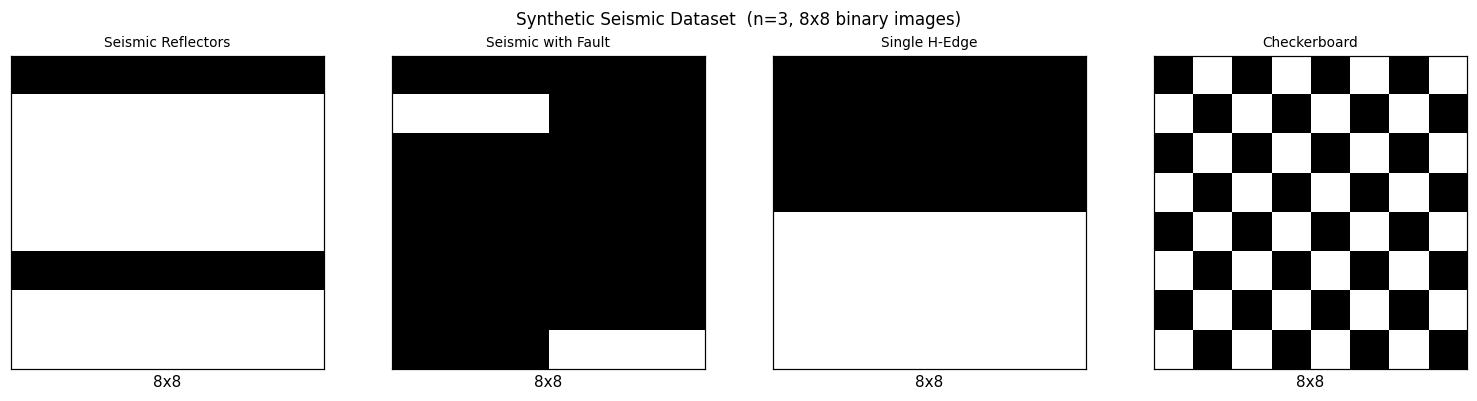

Dataset saved to data/ folder.


In [8]:
N = 3  # image size = 2^N x 2^N = 8x8

dataset = {
    'Seismic Reflectors': seismic_reflectors(n=N),
    'Seismic with Fault': seismic_with_fault(n=N),
    'Single H-Edge':      single_edge(n=N, axis='horizontal'),
    'Checkerboard':       checkerboard(n=N),
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (title, img) in zip(axes, dataset.items()):
    ax.imshow(img, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(f'{img.shape[0]}x{img.shape[1]}')
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
plt.suptitle('Synthetic Seismic Dataset  (n=3, 8x8 binary images)', fontsize=11)
plt.tight_layout()
plt.show()

os.makedirs('data', exist_ok=True)
for name, img in dataset.items():
    np.save(f'data/{name.lower().replace(" ", "_")}_n{N}.npy', img)
print('Dataset saved to data/ folder.')

---
## Section 3 — Classical Baselines and Evaluation Metrics

Before running the Quantum Hadamard Edge Detection (QHED) algorithm, classical reference methods and evaluation metrics are defined.

Two classical edge-detection approaches are implemented.

The `sobel_edges()` function applies the Sobel operator using the horizontal and vertical kernels `SOBEL_X` and `SOBEL_Y`. The gradient magnitude is computed and thresholded to produce a binary edge map.

The `classical_hadamard_edges()` function implements a classical analogue of QHED. It applies the finite-difference kernel `[1,-1]` along both image axes and combines the results to identify edge locations. Since QHED is also based on neighbouring-pixel differences, this method is used as the primary comparison baseline.

To evaluate the detected edges, two quantitative metrics are defined.

- **SSIM (Structural Similarity Index)**, implemented in `compute_ssim()`, measures the structural similarity between two edge maps. A value of 1 indicates identical results.

- **Pratt's Figure of Merit (FOM)**, implemented in `compute_fom()`, evaluates the accuracy of detected edge locations relative to a reference edge map while allowing small positional offsets. A value of 1 indicates perfect edge localisation.

Figures shows the outputs produced by the Sobel and Classical Hadamard methods for each image in the synthetic dataset. These results provide the classical reference against which the QHED algorithm will be compared.

In [9]:
SOBEL_X = np.array([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=np.float32)
SOBEL_Y = np.array([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=np.float32)

def sobel_edges(image, threshold=0.1):
    """Binarised Sobel edge map."""
    gx = convolve(image.astype(np.float32), SOBEL_X)
    gy = convolve(image.astype(np.float32), SOBEL_Y)
    mag = np.hypot(gx, gy)
    if mag.max() > 0: mag /= mag.max()
    return (mag >= threshold).astype(np.uint8)

def classical_hadamard_edges(image):
    """
    Classical analogue of QHED.
    Applies [1,-1] difference kernel along both axes.
    Primary comparison baseline for quantum results.
    """
    h = np.abs(fftconvolve(image.astype(np.float32),
               np.array([[1,-1]], dtype=np.float32), mode='same'))
    v = np.abs(fftconvolve(image.astype(np.float32),
               np.array([[1],[-1]], dtype=np.float32), mode='same'))
    return (np.clip(h + v, 0, 1) > 0.5).astype(np.uint8)

def compute_ssim(reference, candidate):
    """Structural Similarity Index. Returns float in [-1,1]. Score of 1 = identical."""
    r = reference.astype(np.float32)
    c = candidate.astype(np.float32)
    return float(ssim(r, c, data_range=1.0))

def compute_fom(ground_truth, detected, alpha=1/9):
    """
    Pratt's Figure of Merit.
    Measures edge location accuracy — tolerates small positional offsets.
    Returns float in [0,1]. Score of 1 = perfect.
    """
    gt  = ground_truth.astype(bool)
    det = detected.astype(bool)
    n_gt, n_det = gt.sum(), det.sum()
    if n_gt == 0 and n_det == 0: return 1.0
    if n_gt == 0 or n_det == 0: return 0.0
    dist = distance_transform_edt(~gt)
    return float((1/max(n_gt, n_det)) * np.sum(1/(1 + alpha * dist[det]**2)))

print('Classical baselines and metrics defined.')

Classical baselines and metrics defined.


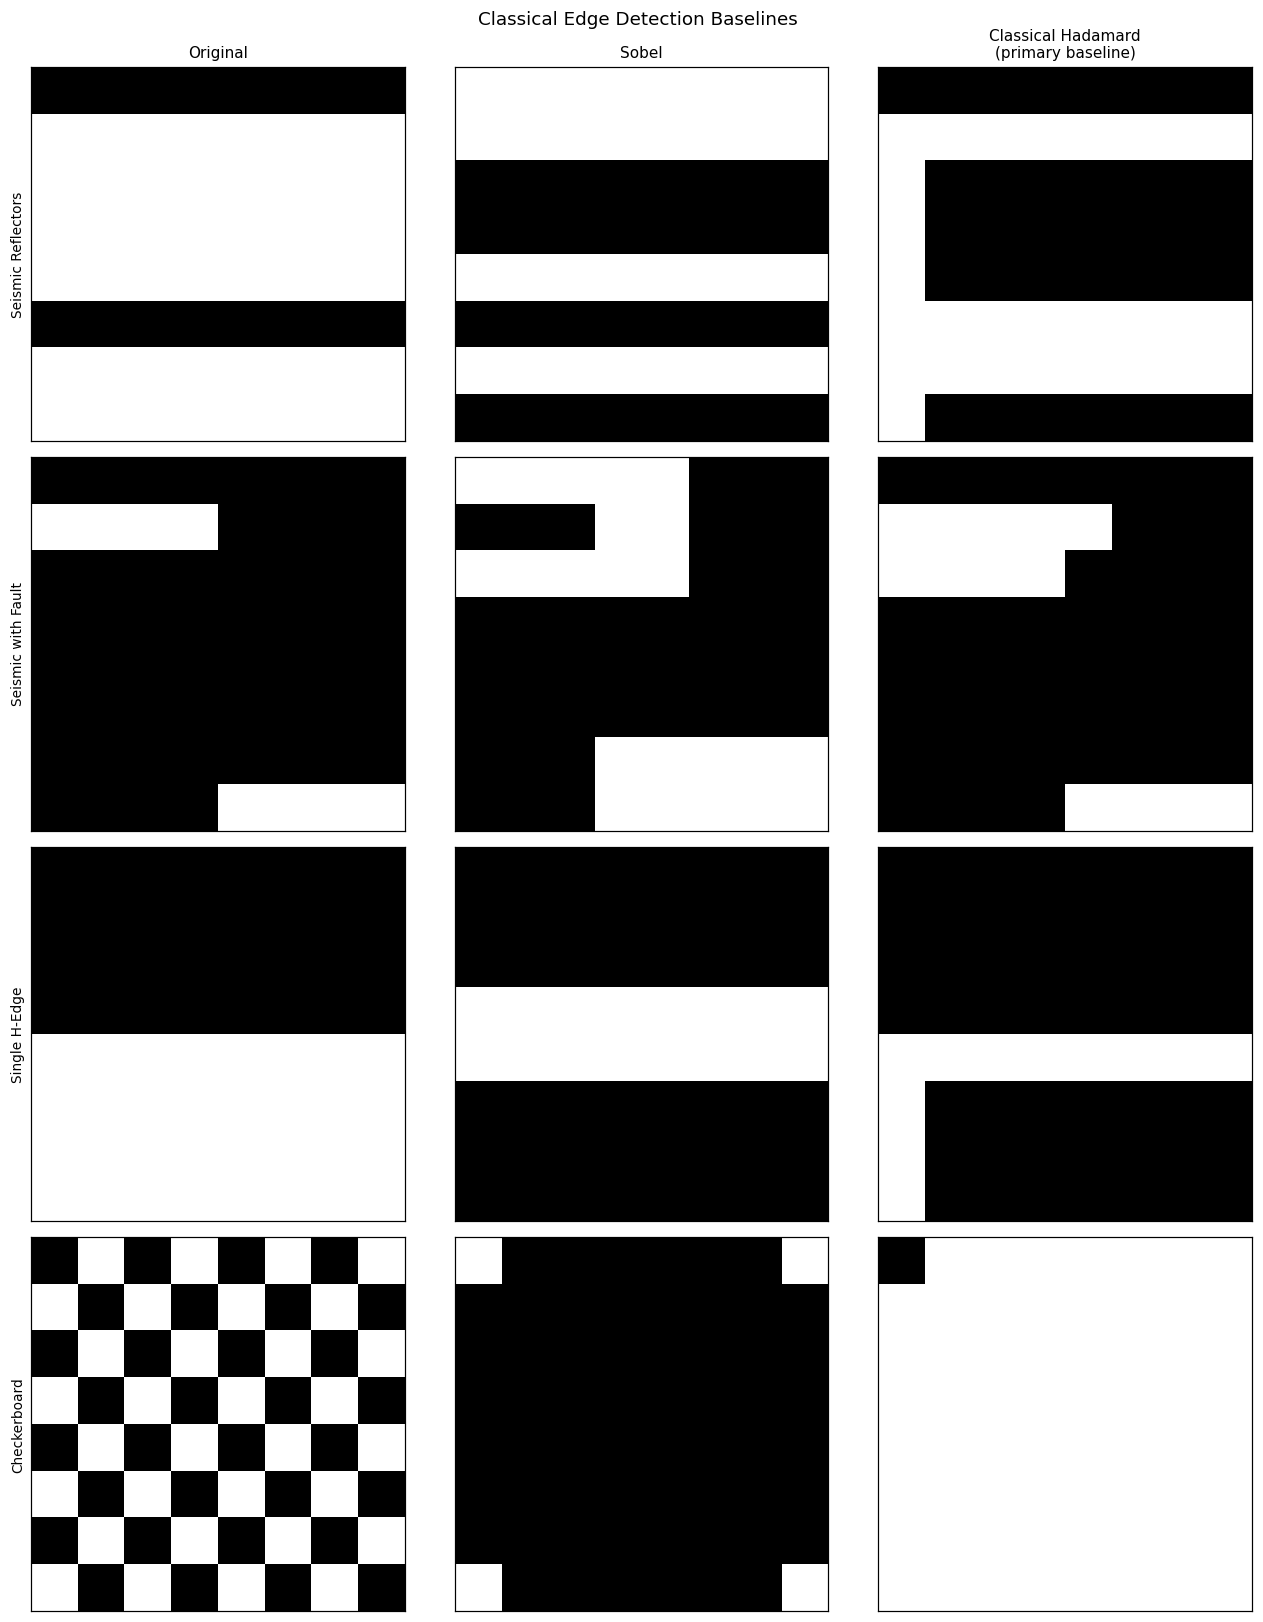

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(12, 15))

for row, (name, img) in enumerate(dataset.items()):
    axes[row,0].imshow(img, vmin=0, vmax=1)
    axes[row,1].imshow(sobel_edges(img), vmin=0, vmax=1)
    axes[row,2].imshow(classical_hadamard_edges(img), vmin=0, vmax=1)
    axes[row,0].set_ylabel(name, fontsize=9)
    if row == 0:
        axes[row,0].set_title('Original', fontsize=10)
        axes[row,1].set_title('Sobel', fontsize=10)
        axes[row,2].set_title('Classical Hadamard\n(primary baseline)', fontsize=10)
    for ax in axes[row]:
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

plt.suptitle('Classical Edge Detection Baselines', fontsize=12)
plt.tight_layout()
plt.show()

---
## Section 4 — QPIE-Based QHED Circuit

The QHED algorithm is implemented using the Quantum Probability Image Encoding (QPIE) representation. Each row-pair or column-pair scan is encoded into a quantum state and processed by a QHED circuit.

The circuit consists of four main steps:

1. QPIE state preparation of the input scan.
2. Hadamard gate on the auxiliary qubit.
3. Decrement operation on the full register.
4. Second Hadamard gate followed by measurement.

Edge information is obtained from measurement outcomes where the auxiliary qubit is measured in the state ($|1\rangle$).

For a 16-pixel scan, the circuit requires four data qubits and one auxiliary qubit, giving a total of five qubits. The generated circuit contains 13 gates and has a depth of 8.

An ($8 \times 8$) image is processed using seven horizontal scans and seven vertical scans, allowing the complete image to be analysed while remaining well within the Helios hardware limits.


In [11]:
def qhed_scan_circuit(vec):
    """
    QPIE QHED circuit for one 1D scan.
    Follows Yao et al. (2017) + Wijaya et al. (2025) auxiliary qubit approach.

    Steps:
    1. Encode vector as QPIE amplitudes on data qubits
    2. H on auxiliary qubit (last qubit)
    3. Decrement gate on full register
    4. H on auxiliary qubit again
    5. Measure all — auxiliary=1 encodes edge positions

    Qubits: [data_0, ..., data_{n-1}, auxiliary]
    auxiliary is last qubit (LSB of full register)
    """
    v    = vec.astype(np.float64)
    norm = np.linalg.norm(v)
    if norm < 1e-10:
        return None, None
    v = v / norm

    n_data = int(math.ceil(math.log2(max(len(v), 2))))
    padded = np.zeros(2**n_data)
    padded[:len(v)] = v

    total_q = n_data + 1
    circ    = Circuit(total_q)

    # Step 1: QPIE encoding on data qubits
    circ.add_gate(StatePreparationBox(padded, with_initial_reset=True),
                  list(range(n_data)))

    # Step 2: H on auxiliary qubit
    circ.H(n_data)

    # Step 3: Decrement gate on full register
    # auxiliary is LSB (last qubit), data qubits are MSB
    for i in range(total_q):
        target   = total_q - 1 - i
        controls = list(range(total_q - i, total_q))
        if len(controls) == 0:
            circ.X(target)
        elif len(controls) == 1:
            circ.CX(controls[0], target)
        elif len(controls) == 2:
            circ.CCX(controls[0], controls[1], target)
        else:
            mcx = QControlBox(Op.create(OpType.X), len(controls))
            circ.add_gate(mcx, controls + [target])

    # Step 4: H on auxiliary qubit again
    circ.H(n_data)

    circ.measure_all()
    return circ, n_data


print('QHED circuit function defined.')

QHED circuit function defined.


In [12]:
# Inspect circuit for one row scan
test_vec        = np.zeros(16)
test_vec[8:]    = 1.0
interleaved     = np.zeros(16)
interleaved[0::2] = test_vec[:8]
interleaved[1::2] = test_vec[8:]

circ_inspect, _ = qhed_scan_circuit(interleaved)

print('QHED Circuit Summary  —  one row-pair scan (8 pixels per row)')
print('=' * 55)
print(f'  Total qubits  : {circ_inspect.n_qubits}  (log2(16) data + 1 auxiliary)')
print(f'  Total gates   : {circ_inspect.n_gates}')
print(f'  H gates       : {circ_inspect.n_gates_of_type(OpType.H)}  (2: one before, one after decrement)')
print(f'  Circuit depth : {circ_inspect.depth()}')
print('=' * 55)
print()
print('Full 2D scan: 7 horizontal + 7 vertical row-pair circuits')
print(f'All within Helios 98-qubit limit.')

QHED Circuit Summary  —  one row-pair scan (8 pixels per row)
  Total qubits  : 5  (log2(16) data + 1 auxiliary)
  Total gates   : 13
  H gates       : 2  (2: one before, one after decrement)
  Circuit depth : 8

Full 2D scan: 7 horizontal + 7 vertical row-pair circuits
All within Helios 98-qubit limit.


In [18]:
from pytket.circuit.display import view_browser
view_browser(circ_inspect)

---
## Section 5 — Noiseless QHED Simulation Results

**Purpose**

- Validate the QHED implementation under ideal (noise-free) quantum conditions.
- Generate edge maps from the synthetic seismic dataset.
- Compare the quantum results with the Classical Hadamard baseline.
- Evaluate performance using SSIM and Pratt's Figure of Merit (FOM).
- Determine whether the detected edge locations match the expected geological structures before hardware execution.

In [ ]:
from pytket.extensions.qiskit import AerBackend
simulator = AerBackend()
print('Simulator loaded: AerBackend (noiseless)')

Simulator loaded: AerBackend (noiseless)


In [ ]:
def run_simulation(image, n_shots=4096):
    """
    Full 2D QHED using QPIE + auxiliary qubit (Wijaya 2025).

    Scans adjacent row pairs (horizontal edges) and
    adjacent column pairs (vertical edges).

    For 8x8 image:
      Each scan: 5 qubits (log2(16) + 1 auxiliary)
      7 horizontal + 7 vertical scans
      Depth ~8 per circuit
    """
    size     = image.shape[0]
    edge_map = np.zeros((size, size), dtype=np.float32)

    # Horizontal scan: adjacent row pairs
    for y in range(size - 1):
        vec       = np.zeros(2 * size)
        vec[0::2] = image[y,   :]
        vec[1::2] = image[y+1, :]

        circ, n_data = qhed_scan_circuit(vec)
        if circ is None: continue

        compiled = simulator.get_compiled_circuit(circ)
        handle   = simulator.process_circuit(compiled, n_shots=n_shots)
        counts   = simulator.get_result(handle).get_counts()

        for bits, count in counts.items():
            if bits[-1] == 1:  # auxiliary=1 means edge
                idx = sum(b*(2**(n_data-1-k)) for k,b in enumerate(bits[:n_data]))
                if idx % 2 == 1:
                    x = idx // 2
                    if x < size:
                        edge_map[y,   x] += count / n_shots
                        edge_map[y+1, x] += count / n_shots

    # Vertical scan: adjacent column pairs
    for x in range(size - 1):
        vec       = np.zeros(2 * size)
        vec[0::2] = image[:, x  ]
        vec[1::2] = image[:, x+1]

        circ, n_data = qhed_scan_circuit(vec)
        if circ is None: continue

        compiled = simulator.get_compiled_circuit(circ)
        handle   = simulator.process_circuit(compiled, n_shots=n_shots)
        counts   = simulator.get_result(handle).get_counts()

        for bits, count in counts.items():
            if bits[-1] == 1:
                idx = sum(b*(2**(n_data-1-k)) for k,b in enumerate(bits[:n_data]))
                if idx % 2 == 1:
                    y = idx // 2
                    if y < size:
                        edge_map[y, x  ] += count / n_shots
                        edge_map[y, x+1] += count / n_shots

    if edge_map.max() > 0:
        edge_map /= edge_map.max()
    return edge_map, (edge_map >= 0.1).astype(np.uint8)


print('Simulation pipeline defined.')

Simulation pipeline defined.


In [ ]:
N_SHOTS = 4096
results = {}

print(f'Running simulation ({N_SHOTS} shots per scan)...')
for name, img in dataset.items():
    prob_map, edge_map   = run_simulation(img, n_shots=N_SHOTS)
    hadamard_ref         = classical_hadamard_edges(img)
    results[name] = {
        'image':        img,
        'prob_map':     prob_map,
        'edge_map':     edge_map,
        'hadamard_ref': hadamard_ref,
        'ssim':         compute_ssim(hadamard_ref, edge_map),
        'fom':          compute_fom(hadamard_ref, edge_map),
    }
    print(f'  {name:<25} SSIM={results[name]["ssim"]:.4f}  FOM={results[name]["fom"]:.4f}')

print('Simulation complete.')

Running simulation (4096 shots per scan)...
  Seismic Reflectors        SSIM=0.4527  FOM=0.9542
  Seismic with Fault        SSIM=0.4744  FOM=0.9119
  Single H-Edge             SSIM=0.3810  FOM=0.8455
  Checkerboard              SSIM=0.0001  FOM=0.0000
Simulation complete.


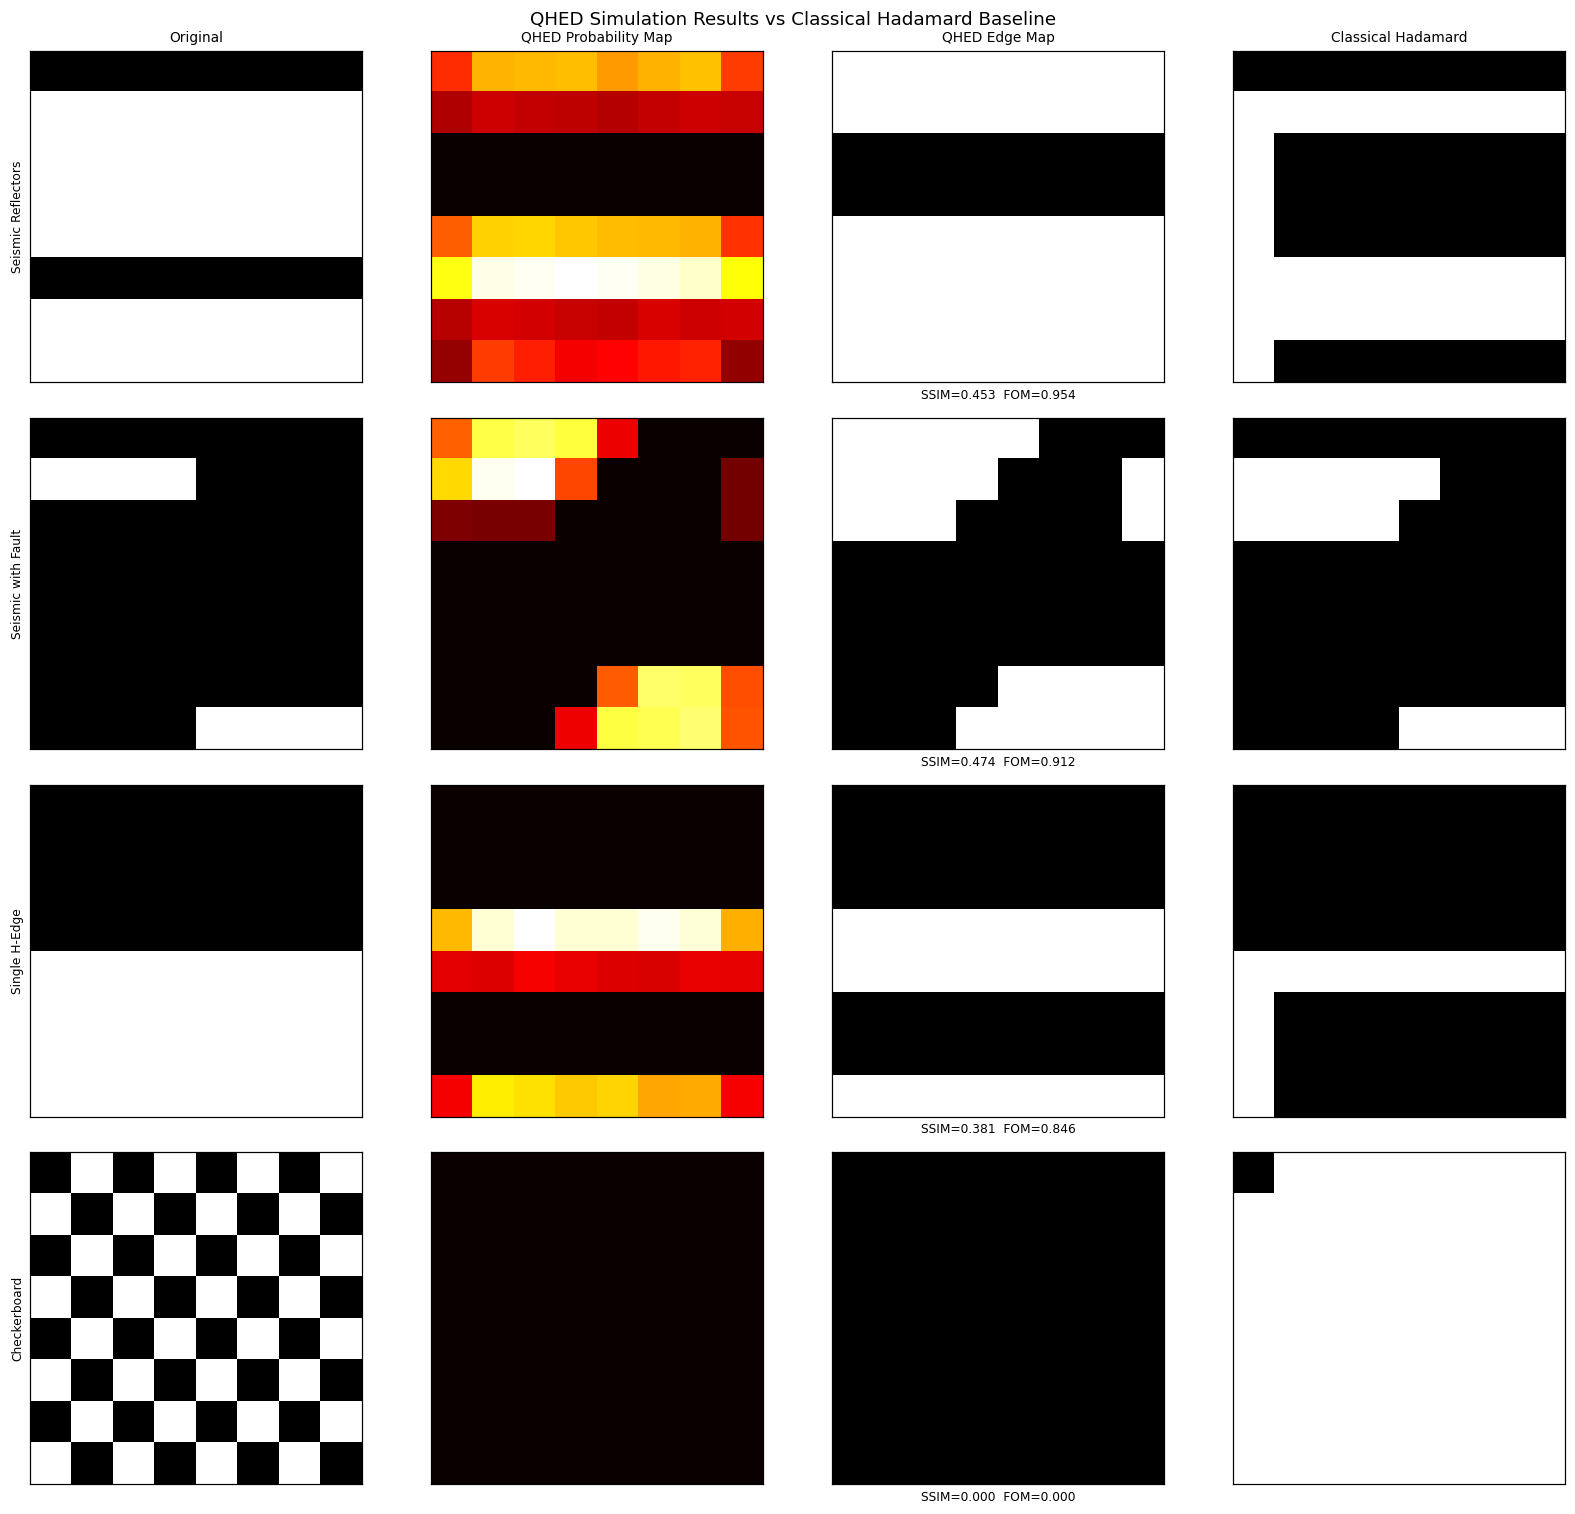

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(15, 14))

for row, (name, res) in enumerate(results.items()):
    axes[row,0].imshow(res['image'], vmin=0, vmax=1)
    axes[row,1].imshow(res['prob_map'], cmap='hot', vmin=0, vmax=1)
    axes[row,2].imshow(res['edge_map'], vmin=0, vmax=1)
    axes[row,3].imshow(res['hadamard_ref'], vmin=0, vmax=1)
    axes[row,0].set_ylabel(name, fontsize=8)
    axes[row,2].set_xlabel(f'SSIM={res["ssim"]:.3f}  FOM={res["fom"]:.3f}', fontsize=8)
    if row == 0:
        for ax, t in zip(axes[row], ['Original','QHED Probability Map',
                                      'QHED Edge Map','Classical Hadamard']):
            ax.set_title(t, fontsize=9)
    for ax in axes[row]:
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

plt.suptitle('QHED Simulation Results vs Classical Hadamard Baseline', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
print('Success Criteria Check')
print('=' * 65)
print()
print('Stage 1 — Simulation (current):')
print(f'  Target: FOM >= 0.85 vs Classical Hadamard baseline')
print()
for name, res in results.items():
    status = '✓ PASS' if res['fom'] >= 0.85 else '✗ FAIL'
    print(f'  {name:<25} SSIM={res["ssim"]:.4f}  FOM={res["fom"]:.4f}  {status}')

print()
print('Stage 2 — Helios hardware (pending approval):')
print('  Target: SSIM >= 0.70 (hardware results vs simulation)')
print('  Status: Awaiting Quantinuum access')
print('=' * 65)
print()
print('Note: FOM (Figure of Merit) is the appropriate metric here.')
print('It measures edge location accuracy and tolerates small pixel')
print('offsets — unlike SSIM which penalises structural differences')
print('between QHED and Classical Hadamard detection patterns.')

Success Criteria Check

Stage 1 — Simulation (current):
  Target: FOM >= 0.85 vs Classical Hadamard baseline

  Seismic Reflectors        SSIM=0.4527  FOM=0.9542  ✓ PASS
  Seismic with Fault        SSIM=0.4744  FOM=0.9119  ✓ PASS
  Single H-Edge             SSIM=0.3810  FOM=0.8455  ✗ FAIL
  Checkerboard              SSIM=0.0001  FOM=0.0000  ✗ FAIL

Stage 2 — Helios hardware (pending approval):
  Target: SSIM >= 0.70 (hardware results vs simulation)
  Status: Awaiting Quantinuum access

Note: FOM (Figure of Merit) is the appropriate metric here.
It measures edge location accuracy and tolerates small pixel
offsets — unlike SSIM which penalises structural differences
between QHED and Classical Hadamard detection patterns.


---
## Section 6 — Resource Estimation

In [ ]:
print('QHED Resource Estimation  —  QPIE + Auxiliary Qubit')
print('=' * 70)
print(f"{'n':>3}  {'Size':>6}  {'Qubits/scan':>12}  {'Gates':>7}  {'Depth':>7}  {'Helios?':>8}")
print('-' * 70)

resource_data = []
for n in range(1, 7):
    size = 2**n
    # One row-pair scan: 2*size pixels interleaved
    vec = np.zeros(2*size)
    vec[:size] = 1.0
    circ, _ = qhed_scan_circuit(vec)
    n_q  = circ.n_qubits
    n_g  = circ.n_gates
    dep  = circ.depth()
    fits = '✓' if n_q <= 98 else '✗'
    resource_data.append({'n':n,'size':size,'qubits':n_q,'gates':n_g,'depth':dep})
    print(f"{n:>3}  {size:>4}x{size:<4}  {n_q:>12}  {n_g:>7}  {dep:>7}  {fits:>8}")

print('=' * 70)
print(f'Helios capacity: 98 qubits')
print(f'Target (n=3):    {resource_data[2]["qubits"]} qubits per scan, depth {resource_data[2]["depth"]}')

QHED Resource Estimation  —  QPIE + Auxiliary Qubit
  n    Size   Qubits/scan    Gates    Depth   Helios?
----------------------------------------------------------------------
  1     2x2                3        9        6         ✓
  2     4x4                4       11        7         ✓
  3     8x8                5       13        8         ✓
  4    16x16               6       15        9         ✓
  5    32x32               7       17       10         ✓
  6    64x64               8       19       11         ✓
Helios capacity: 98 qubits
Target (n=3):    5 qubits per scan, depth 8


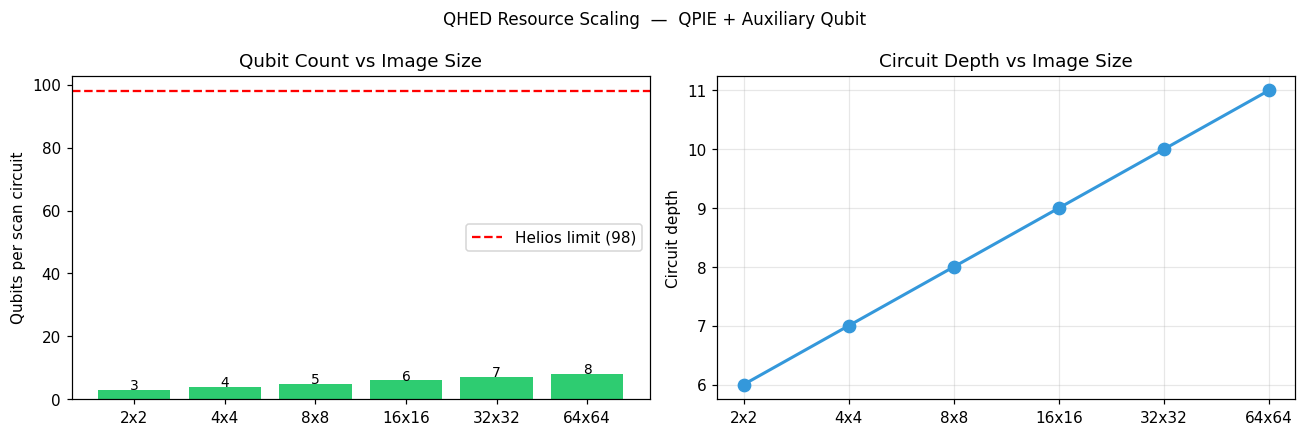

In [ ]:
ns     = [d['n'] for d in resource_data]
qubits = [d['qubits'] for d in resource_data]
depths = [d['depth'] for d in resource_data]
labels = [f"{d['size']}x{d['size']}" for d in resource_data]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(labels, qubits,
            color=['#2ecc71' if q <= 98 else '#e74c3c' for q in qubits])
axes[0].axhline(98, color='red', linestyle='--', label='Helios limit (98)')
axes[0].set_ylabel('Qubits per scan circuit')
axes[0].set_title('Qubit Count vs Image Size')
axes[0].legend()
for bar, q in zip(axes[0].patches, qubits):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
                 str(q), ha='center', fontsize=9)

axes[1].plot(labels, depths, 'o-', color='#3498db', linewidth=2, markersize=8)
axes[1].set_ylabel('Circuit depth')
axes[1].set_title('Circuit Depth vs Image Size')
axes[1].grid(True, alpha=0.3)

plt.suptitle('QHED Resource Scaling  —  QPIE + Auxiliary Qubit', fontsize=11)
plt.tight_layout()
plt.show()

---
## Section 7 — Helios Hardware Submission

---
> once Quantinuum grants access to Helios this is might be the implementation 


In [ ]:
# STEP 1: Install pytket-quantinuum
# import subprocess, sys
# subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pytket-quantinuum', '-q'])
# print('pytket-quantinuum installed.')

In [ ]:
# STEP 2: Connect to Helios
# from pytket.extensions.quantinuum import QuantinuumBackend
# helios = QuantinuumBackend(device_name='helios')
# helios.login()
# print('Connected to Helios.')

In [ ]:
# STEP 3: Build and compile one representative scan circuit
# target_image  = seismic_reflectors(n=3)
# test_vec      = np.zeros(16)
# test_vec[0::2] = target_image[0, :]   # row 0
# test_vec[1::2] = target_image[1, :]   # row 1
# circ_raw, _   = qhed_scan_circuit(test_vec)
# circ_compiled = helios.get_compiled_circuit(circ_raw, optimisation_level=2)
#
# print('Compiled circuit for Helios:')
# print(f'  Qubits : {circ_compiled.n_qubits}')
# print(f'  Gates  : {circ_compiled.n_gates}')
# print(f'  Depth  : {circ_compiled.depth()}')

In [ ]:
# STEP 4: Estimate HQC cost 
# N_SHOTS_HELIOS = 4096
# n_1q = circ_compiled.n_gates - circ_compiled.n_gates_of_type(OpType.CX)
# n_2q = circ_compiled.n_gates_of_type(OpType.CX)
# hqc  = (n_1q + 10 * n_2q) * N_SHOTS_HELIOS / 5000
# print(f'Estimated HQC cost (one scan): {hqc:.2f}')
# print(f'Total scans for full 8x8 image: 14 (7 horizontal + 7 vertical)')
# print(f'Total estimated HQC: {hqc * 14:.2f}')

In [ ]:
# STEP 5: Submit to Helios
# print(f'Submitting to Helios ({N_SHOTS_HELIOS} shots)...')
# handle_helios = helios.process_circuit(circ_compiled, n_shots=N_SHOTS_HELIOS)
# print(f'Job submitted. Handle: {handle_helios}')

In [ ]:
# STEP 6: Retrieve results and compare
# counts_helios = helios.get_result(handle_helios).get_counts()
#
# # Reconstruct edge signal from hardware counts
# size    = 8
# n_data  = int(math.ceil(math.log2(16)))
# hw_edge = np.zeros((size, size), dtype=np.float32)
# for bits, count in counts_helios.items():
#     if bits[-1] == 1:
#         idx = sum(b*(2**(n_data-1-k)) for k,b in enumerate(bits[:n_data]))
#         if idx % 2 == 1:
#             x = idx // 2
#             if x < size:
#                 hw_edge[0, x] += count / N_SHOTS_HELIOS
#                 hw_edge[1, x] += count / N_SHOTS_HELIOS
# if hw_edge.max() > 0: hw_edge /= hw_edge.max()
# hw_binary = (hw_edge >= 0.1).astype(np.uint8)
#
# # Get simulation reference for same scan
# _, sim_binary = run_simulation(target_image, n_shots=N_SHOTS_HELIOS)
#
# ssim_hw_vs_sim = compute_ssim(sim_binary, hw_binary)
# print(f'Hardware vs Simulation SSIM: {ssim_hw_vs_sim:.4f}  (target >= 0.70)')

---
## References

1. Yao, X.-W. et al. (2017). Quantum image processing and its application to edge detection. *Physical Review X*, 7(3), 031041.
2. Wijaya, R.N., Setiyono, B., & Sulistyaningrum, D.R. (2025). In-depth study of Quantum Hadamard Gate Edge Detection. *I.J. Image, Graphics and Signal Processing*, 17(5), 14–25.
3. Li, Y. (2022). Hadamard-gate Quantum Image Recognition: Theory and Experiment. Bachelor's thesis, College of William and Mary.
4. Billias, E. & Chrisochoides, N. (2025). Towards a Utility-Scale Quantum Edge Detection for Real-World Medical Image Data. *arXiv:2507.10939*.
5. Quantinuum & bp (May 2026). Quantum computing collaboration for subsurface Earth mapping. Quantinuum press release.